# Anvendt KI og ML: Innsendingsoppgave – Bildeklassifisering
Velkommen til denne Jupyter notebooken, som du skal bruke til den andre obligatoriske innsendingsoppgaven i Høyskolen Kristianias emne «Anvendt kunstig intelligens og maskinlæring».

## Hvordan du bruker denne notebooken 
Du skal gå gjennom denne notebooken for å løse innsendingsoppgaven. Underveis skal du skrive kode som løser hver av de 13 kodeoppgavene skrevet _i kursiv_. Skriv kode inn i kodecellen rett under oppgaven, og legg gjerne til flere kodeceller. Du kan finne og gjenbruke relevant kode i andre notebooks i emnet. Du kan eventuelt bruke andre programmeringsspråk etter avtale med veilederen din, men alle kodehint er gitt for Python.

Underveis vil du også finne 11 fritekstoppgaver du må besvare tekstlig. Også disse er skrevet _i kursiv_. De skal besvares i markdowncellene rett under oppgavene. Referer til egen kode der det er relevant.

Hvis du står fast, kontakt veilederen din for å få hjelp til å komme videre (via «Innboks» i hovedmenyen i Canvas, _ikke_ klikk «Lever oppgave»).

Etter at du har lagt inn egen tekst og kode for hver oppgave, skal du levere inn en PDF-versjon av denne notebooken. PDF-en skal vise både den skriftlige besvarelsen din og output fra alle kodecellene. Du eksporterer notebooken fra JupyterLab via File-menyen -> Print... I utskriftvinduet velger du «Lagre som PDF» i feltet Destinasjon.

## Problemstilling: Klassifisere bilder som enten teddybjørner eller isbjørner
Oppgaven går ut på å lage en modell som kan klassifisere om bilder tilhører enten kategorien «isbjørn» eller kategorien «teddybjørn». Vi skal teste flere modeller og se hvilken som fungerer best.

## Pakker

In [1]:
# kode fra Anaconda assistent fordi jeg hadde ikke alt installert som ble forutsatt her
#!pip install opencv-python
#!pip install lime
# Denne cellen inneholder nødvendige pakker for å løse oppgavene
import os
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

# Vi velger å ignorere advarsler
import warnings
warnings.filterwarnings('ignore')

from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn import preprocessing
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Conv2D, MaxPool2D, Flatten, Dropout, GlobalMaxPooling2D, BatchNormalization  
from tensorflow.keras.initializers import glorot_normal
from tensorflow.keras.losses import SparseCategoricalCrossentropy
from tensorflow.keras.optimizers import Adam

from efficientnet import tfkeras as efficientnet

from oblig2_functions import (read_images, plot_history, plot_cm, plot_losses, predict_labels, 
                              print_classification_report, set_seed,
                              plot_predicted, show_explanation)

In [2]:
seed = set_seed()

## 1. De første dataene
Mappen «bilder» inneholder en rekke bilder som enten er klassifisert som isbjørner eller som teddybjørner. Vi begynner med et utvalg bilder som ligger i undermappen «data1».

### 1.1. Les inn data

In [3]:
img_polar = read_images('./bilder/data1/polar')
img_teddy = read_images('./bilder/data1/teddy')

### 1.2. Visualiser data

Vis noen bilder for å forstå hvordan data er bygget opp.

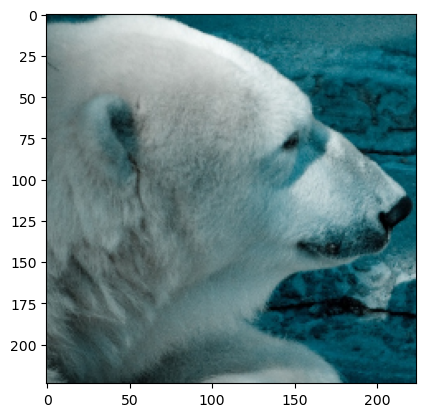

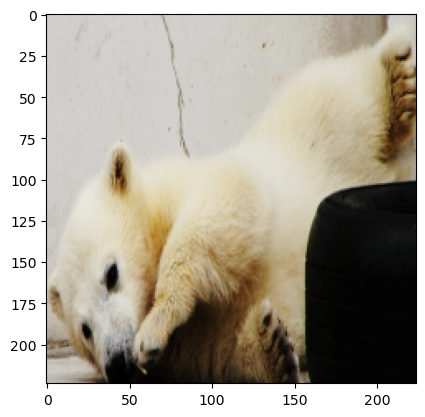

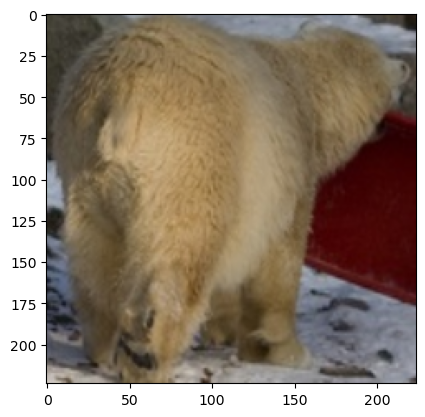

In [4]:
for img in img_polar[:3]:
    plt.imshow(img)
    plt.show()

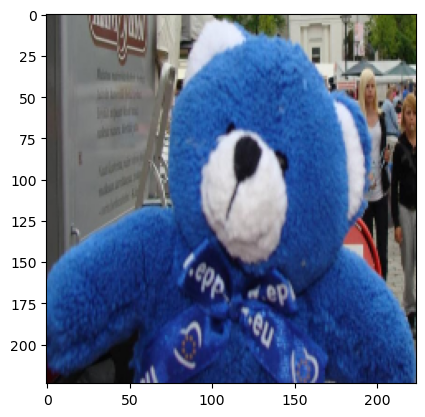

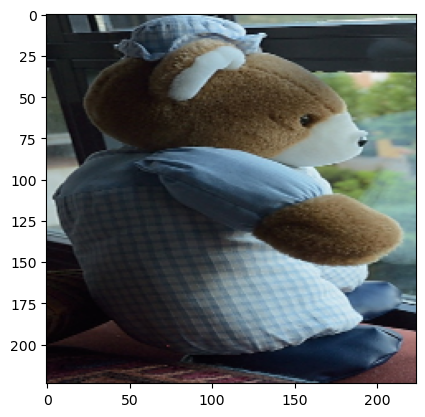

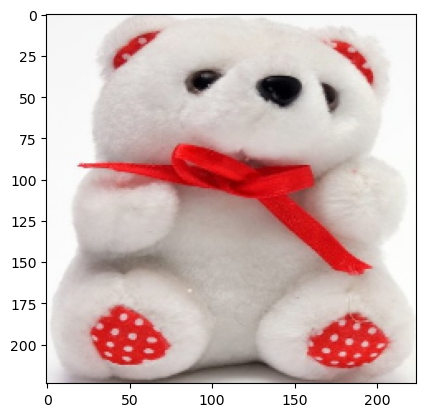

In [5]:
for img in img_teddy[:3]:
    plt.imshow(img)
    plt.show()

_**Kodeoppgave 1**:_
- _Få en rask oversikt over datasettet: Hvor mange bilder er klassifisert som isbjørner, og hvor mange er klassifisert som teddybjørner?_

In [6]:
# Studentkode: 
img_polar.shape

(212, 224, 224, 3)

In [7]:
#Studenkode
img_teddy.shape

(29, 224, 224, 3)

### 1.3. Merk hvert bilde med en kategori

Her definerer vi isbjørner som 0 og teddybjørner som 1.

In [8]:
# Først lager vi en dictionary som forteller at isbjørner er klasse 0 og teddybjørner er klasse 1:
class_dict = dict({
    0: 'polar',
    1: 'teddy'
})

# Vi lager lister over klasse-verdier og klasse-navner til senere bruk
label_bool = list(class_dict.keys())
label_names = list(class_dict.values())

class_dict

{0: 'polar', 1: 'teddy'}

In [9]:
# Vi legger sammen bildene av isbjørner og bildene av teddybjørner
img_all = np.concatenate([img_polar, img_teddy])

In [10]:
# Vi trenger også arrays med label-verdier. Disse lager vi med np.zeros and np.ones. 
# Her er det lurt å dobbeltsjekke at verdiene er de samme som i dictionary.

labels_polar = np.zeros(len(img_polar)) # Opprett array med null for alle bilder i img_polar
labels_teddy = np.ones(len(img_teddy)) # Opprett array med én for alle bilder i img_teddy
labels_all = np.concatenate([labels_polar, labels_teddy]) # Legg alle labels sammen i ett array

### 1.4 Del inn dataene i trenings-, validerings- og testdata

_**Kodeoppgave 2**:_

- _Del inn data i treningsdata (64 %), valideringdata (16 %) og testdata (20 %) ved å bruke funksjonen `train_test_split()`. De nye variablene skal hete henholdsvis `X_train`, `y_train`, `X_val`, `y_val`, `X_test` og `y_test`._

> **Hint**: Bruk `train_test_split()` _to_ ganger for å få tre separate datasett. Sett argumentene `test_size` og `random_state` som `test_size=0.2` og `random_state=seed` _begge gangene_.

In [11]:
# Studentkode
# Deler datasettet i trenings+validering (80%) og test (20%)
X_t_V, X_test, y_t_V, y_test = train_test_split(img_all, labels_all, test_size=0.20, random_state=seed)

In [12]:
#Studentkode
# Deler trenings+validering i trening (80%) og validering(20% ) som samsvarer 64% og 16% av all data
X_train, X_val, y_train, y_val = train_test_split(X_t_V, y_t_V, test_size=0.20, random_state=seed)

# Nå har vi:
# X_train, y_train: 64% av datasettet
# X_val, y_val: 16% av datasettet
# X_test, y_test: 20% av datasettet


_**Kodeoppgave 3**:_

- _Vi ønsker å normalisere dataene slik at hver piksel i bildet får en verdi mellom 0 og 1. Ettersom bilder per definisjon består av tre kanaler med pikselverdier mellom 0 og 255, er det enkelt å normalisere ved å dele alle verdier på 255, for eksempel: `X = X/255`. De nye variablene skal også hete `X_train`, `X_val` og `X_test`._

In [13]:
# Studentkode

# fra modul2Regresjon
#sc_X = MinMaxScaler(feature_range=(0,1))
#sc_y = MinMaxScaler(feature_range=(0,1))
#X_train_scaled = pd.DataFrame(sc_X.fit_transform(X_train.values), columns=X_feat)
#y_train_scaled = pd.DataFrame(sc_y.fit_transform(y_train.values), columns=y_feat)
#X_val_scaled = pd.DataFrame(sc_X.transform(X_val.values), columns=X_feat)
#y_val_scaled = pd.DataFrame(sc_y.transform(y_val.values), columns=y_feat)
#X_test_scaled = pd.DataFrame(sc_X.transform(X_test.values), columns=X_feat)

X_train = X_train / 255.0
X_val = X_val / 255.0
X_test = X_test / 255.0

## 2. Første modell

Vi starter med et nevralt nettverk, som vi kaller `model_1`. 

In [14]:
# Vi lager en funksjon som genererer et nevralt nettverk. Her trenger du ikke endre noe.
# Funksjonen kan gi noen varsler om bruk av CPU. Disse kan du ignorere.

def create_model():
    """
    Defines the neural network.
    We will be using the same model over the assignment, so we will define it here for consistency.
    """
    
    seed = set_seed()
    
    model = Sequential()
    model.add(Conv2D(32,3,padding="same", activation="relu", input_shape=(224,224,3)))
    model.add(MaxPool2D())

    model.add(Conv2D(32, 3, padding="same", activation="relu"))
    model.add(MaxPool2D())

    model.add(Conv2D(64, 3, padding="same", activation="relu"))
    model.add(MaxPool2D())
    model.add(Dropout(0.4, seed=seed))

    model.add(Flatten())
    model.add(Dense(128,activation="relu", kernel_initializer=glorot_normal(seed=seed)))
    model.add(Dense(2, activation="softmax", kernel_initializer=glorot_normal(seed=seed)))
    
    opt = Adam(learning_rate=0.0001)
    model.compile(optimizer=opt, loss=SparseCategoricalCrossentropy(), 
                  metrics=['accuracy'])

    
    return model


In [15]:
model_1 = create_model()

_**Kodeoppgave 4**:_

- _Bruk `summary()` fra klassen `tenforflow.keras.Model()` til å få mer innsikt i modellen._

In [16]:
# Studentkode

model_1.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 50176)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     6,422,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,451,554 (24.61 MB)

 Trainable params: 6,451,554 (24.61 MB)

 Non-trainable params: 0 (0.00 B)

_**Fritekstoppgave**:_

1. _Rapporter antall konvolusjonslag (convolutional layers) og trenbare parametere (trainable parameters)._

### 2.1. Tren den første modellen

For å trene modellen må vi definere antall epoker. Vi plotter trenings- og valideringstap (loss) mens vi trener, og lagrer i tillegg treningshistorikken for senere bruk.

Treningen kan ta et par minutter.

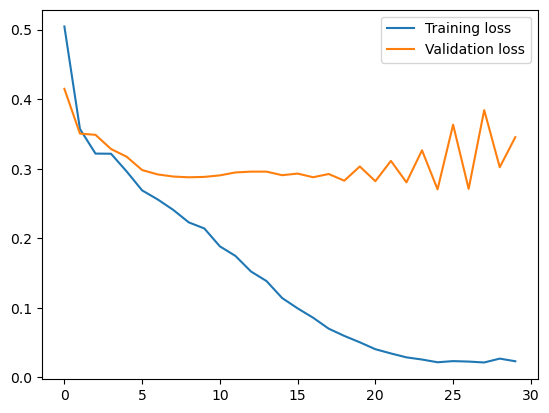

5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 528ms/step - accuracy: 1.0000 - loss: 0.0190 - val_accuracy: 0.8974 - val_loss: 0.3454


In [17]:
n_epochs = 30
history_1 = model_1.fit(X_train, y_train, epochs=n_epochs, validation_data=(X_val, y_val), callbacks=[plot_losses])

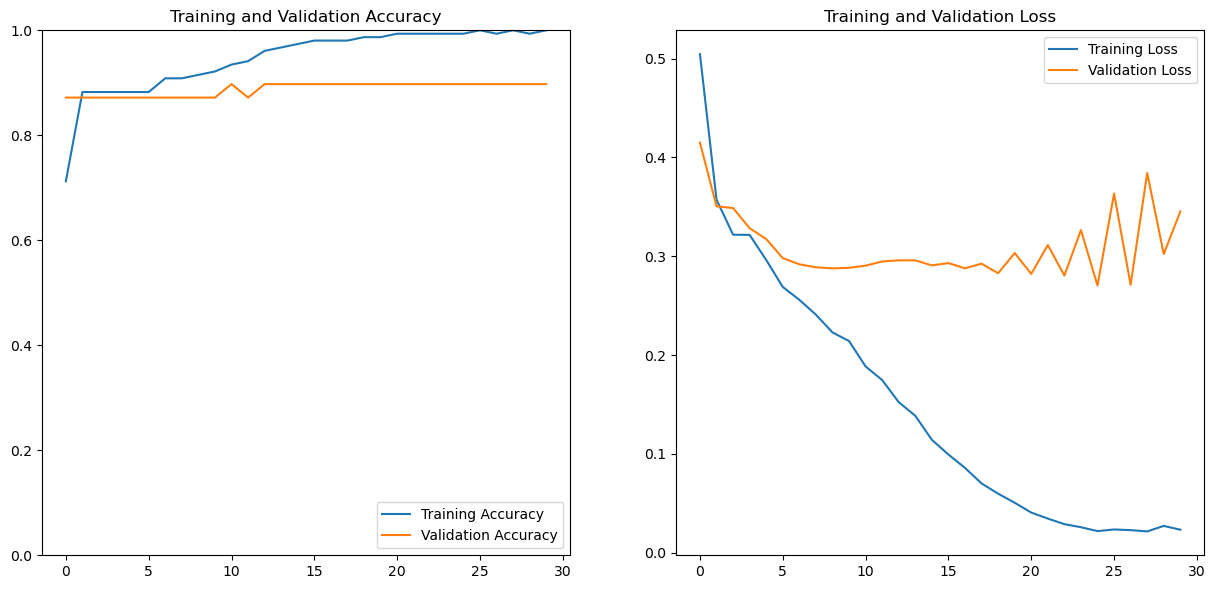

In [18]:
plot_history(history_1)

**Bonusinformasjon** (du kan hoppe over dette hvis du vil): Når modellen er trent, kan du lagre vektene slik at du kan bruke modellen igjen uten å trene den. Neste gang kan du i stedet opprette modellen og laste inn tidligere lagrede vekter.

In [19]:
# Fjern kommentartegn og kjør linjen du vil bruke:
#Lagre vektene i mappen `./models` under navnet `model_1`.  
#model_1.save_weights('./models/model_1')

# Last inn vektene i den kompilerte modellen
#model_1.load_weights('./models/model_1')

### 2.2. Evaluer den første modellen

For å vurdere hvor stor nytte vi har av modellen, må vi evaluere den. Vi starter med å se på confusion matrix.

In [20]:
# Først predikerer vi på testsettet
predictions = predict_labels(X_test, model_1)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 185ms/step


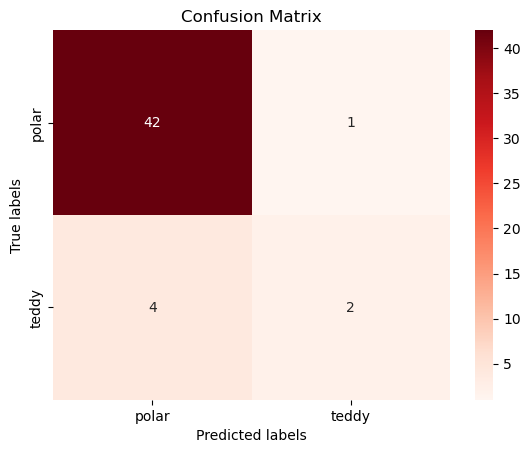

In [21]:
# Plott forvirringsmatrisen
cm = confusion_matrix(y_test, predictions, labels=label_bool)
plot_cm(cm, label_names)

In [22]:
# Vi kan også skrive ut klassifiseringsrapporten
print_classification_report(y=y_test, y_pred=predictions, label_names=label_names)

              precision    recall  f1-score   support

       polar       0.91      0.98      0.94        43
       teddy       0.67      0.33      0.44         6

    accuracy                           0.90        49


_**Fritekstoppgave**:_

2. _Bruk forvirringsmatrisen (confusion matrix) og klassifiseringsrapporten til å rapportere følgende:_
    - _Totalt antall isbjørner i testdataene_
    - _Totalt antall teddybjørner i testdataene_
    - _Antall korrekt klassifiserte isbjørnbilder_
    - _Antall korrekt klassifiserte teddybjørnbilder_
    - _Antall feil klassifiserte isbjørnbilder_
    - _Antall feil klassifiserte teddybjørnbilder_

**Svar**:

Det er total 39 isbjørner i testdataene. Alle 39 ble riktig predikert og 0 isbjørner ble predikert som teddy.
Det er total  9 Teddybjørn i testdataene. Derav 3 riktig predikerte og 6 som ble feil predikert som isbjørn. 
Korrekt klassifiserte isbjørn bilder er 39
Korrekt klassifiserte teddybjørnbider er 3
Feil klassifiserte isbjørnbilder er 0
Feil klassifiserte teddybjørnbilder er 6

## 3. Ekstra data

De fleste modeller kan forbedres med mer data. Vi legger nå til flere bilder med teddybjørner (fra undermappen «data2»). Dette skal vi snart bruke til å lage en ny modell.

In [23]:
img_teddy2 = read_images('./bilder/data2/teddy')
img_all2 = np.concatenate([img_all, img_teddy2])

_**Kodeoppgave 5**:_
- _Lag et nytt array med labels for de nye teddybjørnene (slik vi gjorde tidligere). Navnet skal være `labels_teddy2`. Bruk funksjonen `np.concatenate()` til å tilføye det nye arrayet på slutten av arrayet med tidligere labels. Navnet på det nye arrayet skal være `labels_all2`._

In [24]:
# Studentkode
labels_teddy2 = np.ones(len(img_teddy2))
labels_all2 = np.concatenate([labels_all, labels_teddy2])

_**Kodeoppgave 6**:_
- _Rapporter antall bilder med isbjørner og antall bilder med teddybjørner etter vi har lagt til flere teddybjørner._

In [25]:
#Studentkode
img_teddy2.shape

(88, 224, 224, 3)

In [26]:
img_polar.shape

(212, 224, 224, 3)

_**Kodeoppgave 7**:_
- _Som vi tidligere gjorde for model_1 (punkt 1.4 ovenfor): Del inn de nye dataene i trenings-, validerings- og testdata (men husk å endre på variabelnavnene slik at det er de nye dataene du deler opp), og normaliser  dataene._

In [27]:
# Studentkode
# Deler nytt datasettet i trenings+validering (80%) og test (20%)
X_t_V, X_test, y_t_V, y_test = train_test_split(img_all2, labels_all2, test_size=0.20, random_state=seed)


In [28]:
#Studentkode
# Deler ny trenings+validering i trening (80%) og validering(20% ) som samsvarer 64% og 16% av all data
X_train, X_val, y_train, y_val = train_test_split(X_t_V, y_t_V, test_size=0.20, random_state=seed)


## 4. Andre modell

Vi skal nå trene en ny modell som inkluderer de ekstra dataene. Vi kaller modellen `model_2`.

### 4.1. Tren den andre modellen

In [29]:
# Først bruker vi create_model-funksjonen til å opprette en ny modell
model_2 = create_model()

In [30]:
model_2.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 112, 112, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 56, 56, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 56, 56, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 50176)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     6,422,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,451,554 (24.61 MB)

 Trainable params: 6,451,554 (24.61 MB)

 Non-trainable params: 0 (0.00 B)

_**Kodeoppgave 8**:_
- _Tilpass `model_2` til de nye dataene. Tren i nøyaktig **30 epoker**._

> **NB!** Hvis du utfører `model_2.fit()` mer enn en gang etter kompilering (opprettelse), fortsetter den der den forrige treningen sluttet, og trener dermed flere epoker.

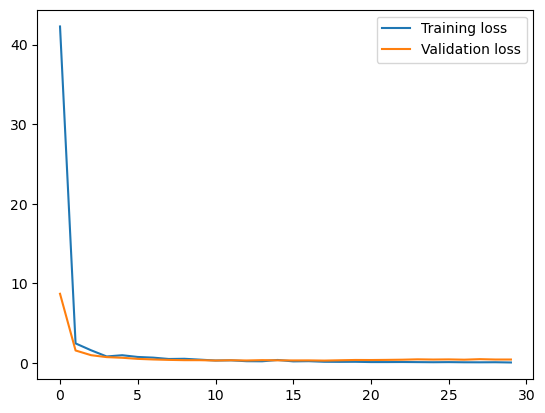

7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 483ms/step - accuracy: 0.9866 - loss: 0.0472 - val_accuracy: 0.9057 - val_loss: 0.4174


In [31]:
# Studentkode

n_epochs = 30
history_1 = model_2.fit(X_train, y_train, epochs=n_epochs, validation_data=(X_val, y_val), callbacks=[plot_losses])


In [32]:
# Se bonusinformasjon om lagrede modeller over.

# Fjern kommentartegn og kjør linjen du vil bruke:
# Lagre vektene i mappen `./models` under navnet `model_2`. 
#model_2.save_weights('./models/model_2')

# Last inn vektene i den kompilerte modellen
#model_2.load_weights('./models/model_2')

### 4.2. Evaluer den andre modellen

_**Kodeoppgave 9**:_
- _Evaluer `model_2` på testdata og plott forvirringsmatrisen (confusion matrix) som for `model_1`. Husk at du må starte med å gjøre en prediksjon på de nye testdataene._

In [33]:
# Studentkode

# Først predikerer vi på testsettet
predictions = predict_labels(X_test, model_2)

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 123ms/step


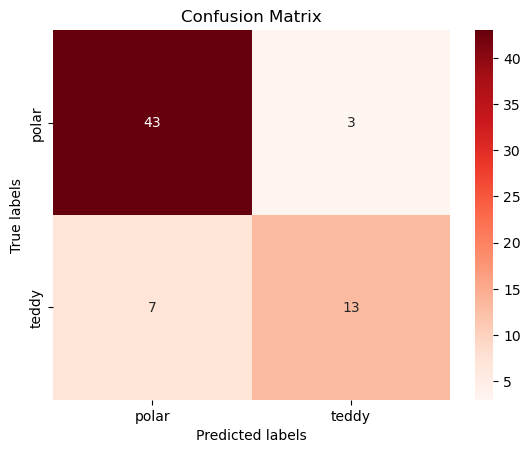

In [34]:
#Studentkode
# Plott forvirringsmatrisen
cm = confusion_matrix(y_test, predictions, labels=label_bool)
plot_cm(cm, label_names)

In [35]:
print_classification_report(y=y_test, y_pred=predictions, label_names=label_names)

              precision    recall  f1-score   support

       polar       0.86      0.93      0.90        46
       teddy       0.81      0.65      0.72        20

    accuracy                           0.85        66


_**Fritekstoppgaver**:_

3. _Hva kan du si om balansen/ubalansen (class imbalance) i datasettet som brukes til å trene modell 1 og modell 2? Er det en av klassene som dominerer, og i så fall hvilken? Er det en av modellene som har mer balanserte data?_

4. _Hvordan påvirker denne balansen/ubalansen modellens prediksjon for hver av klassene? Hvis data er ubalanserte, er det da noe spesielt du kan risikere at modellen lærer å predikere – og i så fall hva?_

5. _Bias-varians-avveining er en avveining mellom modellens evne til å generalisere og evnen til å forklare sammenhenger i dataene, jf. figuren nedenfor. Forklar hvordan vi forventer at treningstap/treningsfeil og valideringstap/valideringsfeil (training error og validation error) endrer seg når vi trener algoritmen. Si noe om følgende:_
    - _Forventer vi høye eller lave tapsverdier/feilverdier på trenings- og valideringsdata i starten av treningen?_
    - _Hva skjer når vi trener modellen over lang tid?_
    - _Når bør vi stoppe å trene, og hvorfor?_
    - _Hvilket tap (dvs. hvilke feilverdier) forventer vi å finne for trenings- og validerings-data hvis vi har en modell som fanger opp all variansen i treningsdataene?_

![Bias-varians-avveining (Kilde: LearnOpenCV)](./figures/bias-varians-oblig2.png)
 (Kilde: LearnOpenCV)

6. _Forklar prosessen med kryssvalidering. Hvilken del av koden for modell 2 ville du ha endret hvis du skulle bruke kryssvalidering? Hvordan er kryssvalidering forskjellig fra enkel oppsplitting i treningsdata, valideringsdata og testdata? Hvilken av disse metodene bør vi stole mest på når vi skal fintune modellen?_

7. _Bruk metrikkene nøyaktighet (accuracy), presisjon (precision) og sensitivitet (recall) til å evaluere modell 1 og modell 2. Forklar hva hver av disse metrikkene sier om modellenes faktiske ytelse for hver klasse. Hvordan vil balansen/ubalansen i klassene påvirke evalueringen?_

**Svar**:

Spørsmål 3 svar: Det er stor ubalanse i begge settene men størst i første datasettet. I første runde har vi 209 isbjørn bilder og kun 28 teddybjørn bilder, dvs omtrent 7,5 ganger så mange isbjørn- enn teddybjørn-bilder. I andre runde har vi fortsatt 209 isbjørn- men nå 87 teedybjørn-bilder. det er om lag 2,5 ganger antall isbjørn.

Spørsmål 4 svar: Når modellen trenes strever den etter å minimere tapet. Ein feil predikert isbjørn utgjør i begge settene en lavere tapsverdi enn en feil predikert teddy. Dette medfører at vi trener modellen til å favorisere prediksjon isbjørn for å minimere tapet.

Spørsmål 5 svar: I starten av trening forventer vi høye tapsverdier av både trenings-og valideringsdata.Trener vi modellen over lang tid går tapsverdiene ned. Tapskurven flater ut for både trenings-og valideringsdata. På ett tidspunkt krysser de 2 kurvene hverandre. Tapsverdier for treningsdata fortsetter å gå ned, mens valideringsdata flater ut langsommere til den begynner å stige igjen. Krysningspunktet mellom de to kurvene er område hvor vi burde stoppe trening og revurdere. Det er her modellen begynner å bli overtilpasset og tar for mye hensyn til støy i treningsdataene som ikke bidrar til en bedre tilpasset generalisering.Når vi fanger opp all variansen i treningsdata, så har vi en overtilpasset modell. Tapet for treningsdata er da tilnærmet null. Tapet for valderingsdata er da veldig høy.

Spørsmål 6 svar: Kryssvalidering betyr at treningsdata og valideringsdata splittes ikke bare en gang, men at vi bruker all data (unntatt de som er lagt bort som testdata) til både trening og validering. Vi deler data i flere folds, for eksempel 5 folds og bruker første fold til validering og de resterende 4 til trening. Så kjører vi en runde til og bruker da andre fold til validering. I tredje runde  3. fold osv.
Delen som må endres er steget etter jeg har lagt bort testdata og delte de resterende data i trenings- og valideringsdata:
#X_train, X_val, y_train, y_val = train_test_split(X_t_V, y_t_V, test_size=0.20, random_state=seed)
Den bør erstattes med kode som ligner på den vi brukte i Modul 3 TreningTestForbedreing notebooken:
#antall_folds = 5
#cv_results = cross_validate(
   #model, X_t_V, y_t_V cv=antall_folds, scoring=(
      # 'r2', 'neg_mean_squared_error'), return_train_score=True)
Når vi har en overtilpasset modell 1, så har vi for høy varians og noe som hjelper imot er mer treningsdata. Dette viser seg allerede i modell 2 som vi har kjørt den fordi vi har brukt mer data. Har vi ikke mer data er kryssvalidering en god metode å dempe overtilpasning siden vi da bruker hele tilgejneglige datastokken til trening og har dermed mer data for trening.  For fintuning av modellen er kryssvalideirng altsp en god metode. 


Spørsmål 7 svar: Accuracy måler hvor stor andel av bildene ble predikert riktig. Vi oppnår i begge rundene en accuracy av 0.88. Den verdien blir misvisende dersom vi har trent modellen til å favorisere prediksjon isbjørn ihht at en feil isbjørn påvirker accuracy verdien mindre enn en feil teddybjørn.
Presisjon måler andelen av korrekt predikerte klasser. I første runde er det 0,87 for isbjørn og 1 for teddybjørn. I runde to er det 0,9 for isbjørn og 0,8 for teddybjørn. 
Sensitivitet måler hvor mange ekte positive som blir korrekt identifisert. I første runde blir alle isbjøen korrekt identifisert, men kun 33% av teddybjørner. I andre runde 94%av isbjørn og 71% av teddybjørn.
Presisjon og Sensitivitet henger tett sammen og for en god modell forventer vi et balansert resultat av begge to. Men hver feil eller riktig predikert teddybjørn påvirker alle tre metrikkene i mye større grad enn isbjørnene gjør og da blir informasjonsnytten av metrikken litt spolert. Den beste hjelpen å få det bedre er å ha mer data og spesielt mer utjevnet ihht klasser. Det vises allerede en del forbedring i modell 2 men for å forbedre likebehandling av klassene bør vi har mer data og fortrinnsvis med forholdsvis like antall av bilder i hver klasse.


## 5. Tredje modell, med overføringslæring

Modellen i `model_create()` er ganske enkel. I stedet ønsker vi å forbedre klassifiseringen ved å bruke en mer komplisert modell som allerede er pre-trent på å klassifesere andre typer bilder. Vi bruker modell-typen `EfficientNetB0` som kan kalles direkte fra keras. Første gang du kaller modellen lastes vektene ned, dvs. at du må ha tilgang på internett.

In [36]:
# Denne koden laster inn ferdigtrent modell og legger til egne lag for å kunne tilpasse seg vårt klassifiseringsproblem:
seed = set_seed()

input_shape = (224,224,3)
nr_outputs = 2
base_model = efficientnet.EfficientNetB0(weights="imagenet", include_top=False, input_shape=input_shape)
base_model.trainable = False

model_3 = Sequential()
model_3.add(base_model)
model_3.add(GlobalMaxPooling2D())
model_3.add(Dense(nr_outputs, activation="softmax", kernel_initializer=glorot_normal(seed=seed)))

opt = Adam(learning_rate=0.0001)
model_3.compile(optimizer=opt, loss=SparseCategoricalCrossentropy(), metrics=["accuracy"])

_**Fritekstoppgaver**:_

8. _Forklar kort hva disse to delene av koden gjør:_
    - `base_model.trainable = False`
    - `include_top=False`

9. _Forklar formålet og prosessen med overføringslæring. På hvilken måte er overføringslæring gunstig for trening av en modell til en ny oppgave? På hvilken måte må arkitekturen til den overførte modellen tilpasses? Hva betyr det å fryse lag, og hvorfor gjør vi det?_

**Svar**:

(Besvar oppgavene her)

### 5.1. Tren den tredje modellen

_**Kodeoppgave 10**:_
- _Tilpass `model_3` til de nye dataene. Tren i nøyaktig **30 epoker**._

> **NB!** Hvis du utfører `model_3.fit()` mer enn en gang etter kompilering (opprettelse), fortsetter den der den forrige treningen sluttet, og trener dermed flere epoker.

In [37]:
# Studentkode

# (Skriv din kode her.)

In [38]:
# Se bonusinformasjon om lagrede modeller over.

# Fjern kommentartegn og kjør linjen du vil bruke:
# Lagre vektene i mappen `./models` under navnet `model_3`. 
#model_3.save_weights('./models/model_3')

# Last inn vektene i den kompilerte modellen
#model_3.load_weights('./models/model_3')

### 5.2. Evaluer den tredje modellen

_**Kodeoppgave 11**:_
- _Evaluer `model_3` på testdata og plott forvirringsmatrisen som for `model_1` og `model_2`. Husk at du må starte med å gjøre en prediksjon på de nye testdataene._

In [39]:
# Studentkode

# (Skriv din kode her.)

In [40]:
print_classification_report(y=y_test, y_pred=predictions, label_names=label_names)

              precision    recall  f1-score   support

       polar       0.86      0.93      0.90        46
       teddy       0.81      0.65      0.72        20

    accuracy                           0.85        66


## 6. Evaluering av modellene ved å se på feilprediksjoner

Vi evaluerer de tre modeller mot hverandre ved å sammenligne klassifiseringsrapportene.

**Merk**: Vi evaluerer alle modellene på testdataene som inneholder  ekstra bilder av teddybjørner. Siden vi trener `model_1` basert på en annen oppdeling av dataene, kan vi få datalekkasje (noen av testdataene ble brukt til trening). Dette er dårlig praksis, og det vil gi en for positiv evaluering av modellen. Vi ser bort fra dette her, fordi `model_1` likevel har dårligst ytelse.

In [41]:
# Prediksjoner fra alle tre modellene på testdata:
predictions_1 = predict_labels(X_test, model_1)
predictions_2 = predict_labels(X_test, model_2)
predictions_3 = predict_labels(X_test, model_3)

2/3 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/stepWARNING:tensorflow:6 out of the last 8 calls to <function TensorFlowTrainer.make_predict_function.<locals>.one_step_on_data_distributed at 0x000001CDEFF67880> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.
3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 137ms/step
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step
3/3 ━━━━━━━━━━━━━━━━━━━━ 12s 2s/step 


In [42]:
print_classification_report(y=y_test, y_pred=predictions_1, label_names=label_names)

              precision    recall  f1-score   support

       polar       0.82      1.00      0.90        46
       teddy       1.00      0.50      0.67        20

    accuracy                           0.85        66


In [43]:
print_classification_report(y=y_test, y_pred=predictions_2, label_names=label_names)

              precision    recall  f1-score   support

       polar       0.86      0.93      0.90        46
       teddy       0.81      0.65      0.72        20

    accuracy                           0.85        66


In [44]:
print_classification_report(y=y_test, y_pred=predictions_3, label_names=label_names)

              precision    recall  f1-score   support

       polar       0.72      0.67      0.70        46
       teddy       0.35      0.40      0.37        20

    accuracy                           0.59        66


_**Kodeoppgave 12**:_
- _Basert på eksempelet fra modell 1, skal du vise bilder for feilklassifiseringer fra modell 2 og 3. For hver modell skal du vise eksempelbilder hvor teddybjørner er predikert som isbjørner og hvor isbjørner er feilklassifisert som teddybjørner (fem felter med kode)._

> **NB**: Undersøk gjerne flere enn 3 bilder per kodefelt (`nr_pic=3`), men når du gjør klar den endelige innleveringsfilen, nøy deg med å vise 3 eksempelbilder per kodefelt.

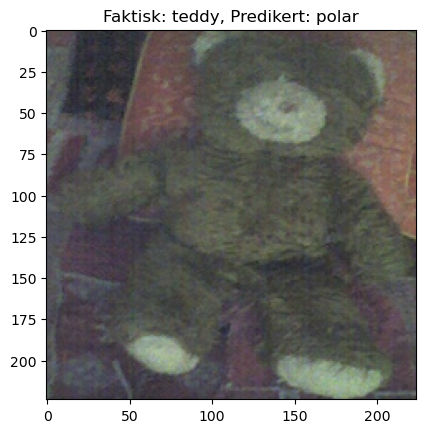

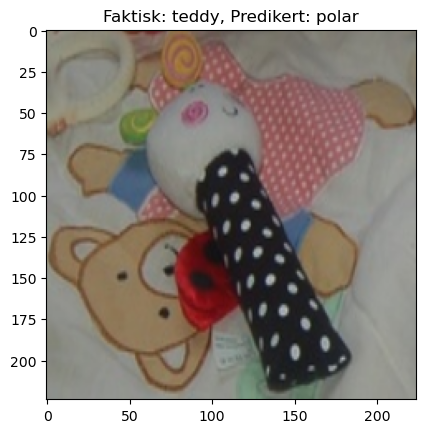

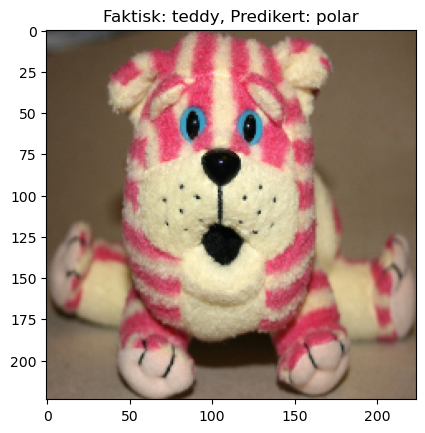

In [45]:
# Modell 1, bilder av teddybjørner klassifisert som isbjørn i modell 1:
plot_predicted(y = y_test, y_pred = predictions_1, X=X_test, real_class=1, pred_class=0, 
               class_dict=class_dict, nr_pic=3)

In [46]:
# Studentkode

# Modell 1, bilder av isbjørner klassifisert som teddybjørn i modell 1:
# (Skriv din kode her.)

In [47]:
# Studentkode

# Modell 2, bilder av teddybjørner klassifisert som isbjørn i modell 2:
# (Skriv din kode her.)

In [48]:
# Studentkode

# Modell 2, bilder av isbjørner klassifisert som teddybjørn i modell 2:
# (Skriv din kode her.)

In [49]:
# Studentkode

# Modell 3, bilder av teddybjørner klassifisert som isbjørn i modell 3:
# (Skriv din kode her.)

In [50]:
# Studentkode

# Modell 3, bilder av isbjørner klassifisert som teddybjørn i modell 3:
# (Skriv din kode her.)

_**Fritekstoppgave**:_

10. _Etter å ha predikert klassene til testbildene, og plottet dem som har blitt feilaktig predikert, kommenter hver av modellene separat: Hva kan du si om bildene som er feilklassifisert? Er noen av disse vanskelig å klassifisere for et menneske? Etter å ha sett på dette: Hvilken av modellene ville du helst ha brukt?_

**Svar**:

(Besvar oppgaven her)

## 7. Forklaring av resultatene ved hjelp av LIME

LIME står for "Local Interpretable Model-agnostic Explanations", og hjelper med å forstå hvilke deler av et bilde som bidrar for eller mot en spesifikk prediksjon av et bilde, for eksempel for en klassifikasjon.

Stegene i LIME er som følger:
1. **LIME lager flere bilder basert på orignialbildet**. Originalbildet deles inn i superpiksler (en sampling av flere piksler), og man genererer flere bilder (samples) hvor noen av disse superpikslene er synlige (resten blir sort). 
2. **Den trente modellen brukes til å predikere hvert sample generert i punkt 1.**
3. **Beregn vekter for hvert sample**. For bilder beregnes vekten som cosinus-distansen mellom det perturberte bilde og originalbildet. Jo mer likhet, dess større er vekten.
4. **En lineær regresjonsmodel tilpasses ved bruk av vektene fra punkt 3 og brukes til å finne de viktigste superpikslene**. Jo større koeffisient, desto viktigere er superpikselen.

Ved å bruke LIME, kan vi bestemme hvilke deler av bildet som er avgjørende for at modellen gir den prediksjonen (klassifiseringen) som den gjør.

For mer informasjon, sjekk: https://towardsdatascience.com/interpreting-image-classification-model-with-lime-1e7064a2f2e5

_**Kodeoppgave 13**:_
- _Funksjonen `show_explanation()` som ligger i Python-filen `oblig2_functions.py` kan brukes til å forklare hvilke deler av et bilde som bidrar **for eller imot** en prediksjon av den korrekte klassen til bildet. Sett deg inn i argumentene som funksjonen trenger, og bruk funksjonen til å vise superpiksler for og imot korrekt label for bildet `X_test[1]` for `model_1` og `model_3`._

> **Hint**: Du trenger å kalle `show_explanation()` to ganger for _hver modell_ for å besvare oppgaven.

In [51]:
# Studentkode

# Modell 1: Hvilke deler bidrar til en prediksjon av den korrekte klassen?
# (Skriv din kode her.)

In [52]:
# Studentkode

# Modell 1: Hvilke deler bidrar imot en prediksjon av den korrekte klassen?
# (Skriv din kode her.)

In [53]:
# Studentkode

# Modell 3: Hvilke deler bidrar til en prediksjon av den korrekte klassen?
# (Skriv din kode her.)

In [54]:
# Studentkode

# Modell 3: Hvilke deler bidrar imot en prediksjon av den korrekte klassen?
# (Skriv din kode her.)

_**Fritekstoppgave**:_

11. _Beskriv hva du finner for begge tilfellene og begge modellene._

**Svar**:

(Besvar oppgaven her)